In [1]:
!pip install tensorflow scikit-learn matplotlib seaborn

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
Dense,
    Flatten,
    Input,
    Dropout,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.0


In [5]:
#  Load CIFAR-10
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.cifar10.load_data()

print("Training images:", X_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1470s 9us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test images: (10000, 32, 32, 3)
Test labels: (10000, 1)


In [7]:
# Define class names
class_names = [
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'
]

for label, name in enumerate(class_names):
    print(label, "->", name)

0 -> airplane
1 -> automobile
2 -> bird
3 -> cat
4 -> deer
5 -> dog
6 -> frog
7 -> horse
8 -> ship
9 -> truck


In [11]:
#  Reshape labels
# CIFAR-10 labels have shape (50000, 1), 
# but Keras and scikit-learn usually work better
# with shape (50000,)

y_train_full = y_train_full.ravel()
y_test = y_test.ravel()

print("Training labels shape:", y_train_full.shape)
print("Test labels shape:", y_test.shape)

Training labels shape: (50000,)
Test labels shape: (10000,)


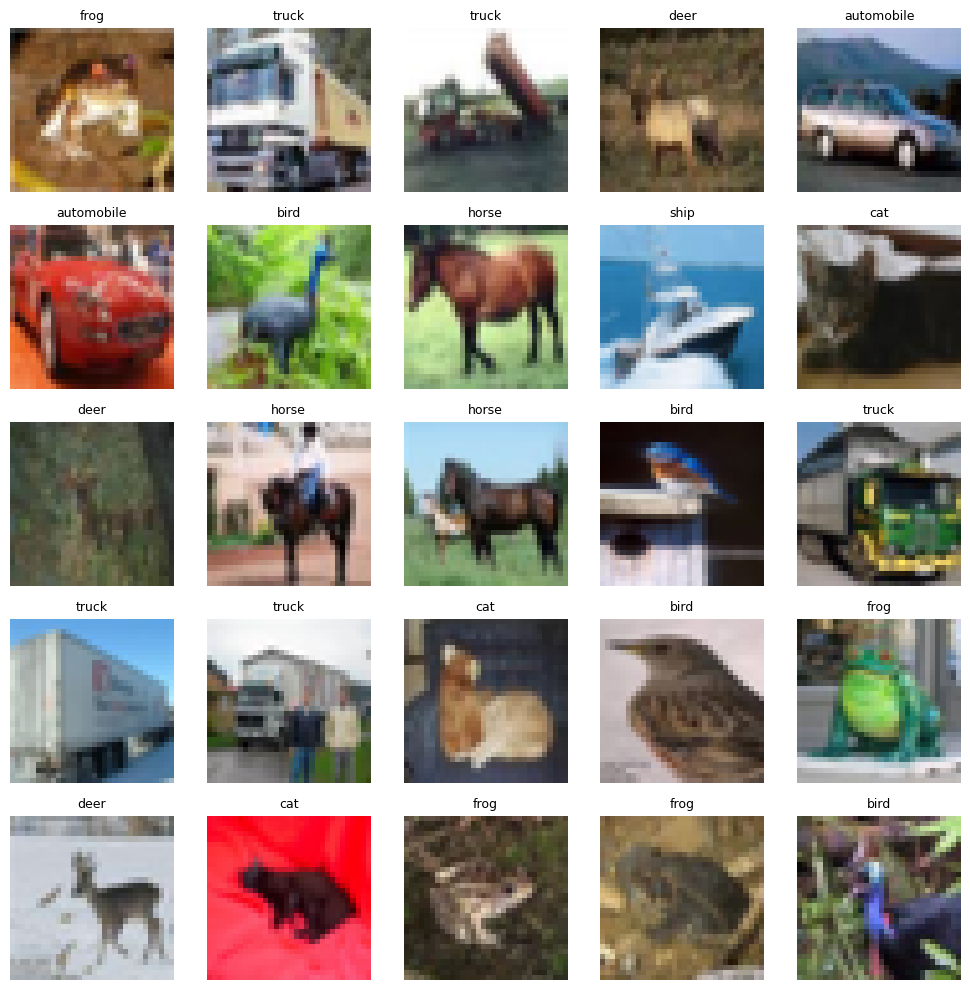

In [12]:
# Display sample images
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_full[i])
    plt.title(class_names[y_train_full[i]], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
#  Check pixel values and labels
import pandas as pd
print("Minimum pixel value:", X_train_full.min())
print("Maximum pixel value:", X_train_full.max())
print("Unique labels:", np.unique(y_train_full))
print("Class counts:")
print(pd.Series(y_train_full).value_counts().sort_index())


Minimum pixel value: 0
Maximum pixel value: 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]
Class counts:
0    5000
1    5000
2    5000
3    5000
4    5000
5    5000
6    5000
7    5000
8    5000
9    5000
Name: count, dtype: int64


In [18]:
# Scale pixel values
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("New minimum:", X_train_full.min())
print("New maximum:", X_train_full.max())

New minimum: 0.0
New maximum: 1.0


In [21]:
#  Create validation set
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (40000, 32, 32, 3)
Validation set: (10000, 32, 32, 3)
Test set: (10000, 32, 32, 3)


In [22]:
# Build dense baseline model
dense_model = Sequential([
    Input(shape=(32,32,3)),
    Flatten(),
    
    Dense(512, activation='relu'),
    Dropout(0.3),
    
    Dense(256, activation='relu'),
    Dropout(0.3),
    
    Dense(10, activation='softmax')
])

dense_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

dense_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       1,573,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# 32 × 32 × 3 image
#         ↓
# Flatten: 3,072 values
#         ↓
# Dense: 512 neurons + ReLU
#         ↓
# Dropout: 30%
#         ↓
# Dense: 256 neurons + ReLU
#         ↓
# Dropout: 30%
#         ↓
# Dense: 10 neurons + softmax


In [24]:
# Train dense model
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history_dense = dense_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.2393 - loss: 2.0576 - val_accuracy: 0.2919 - val_loss: 1.9261
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.2871 - loss: 1.9261 - val_accuracy: 0.3322 - val_loss: 1.8451
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.3106 - loss: 1.8783 - val_accuracy: 0.3638 - val_loss: 1.8101
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.3201 - loss: 1.8567 - val_accuracy: 0.3699 - val_loss: 1.7785
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.3296 - loss: 1.8353 - val_accuracy: 0.3672 - val_loss: 1.7756
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.3352 - loss: 1.8159 - val_accuracy: 0.3799 - val_loss: 1.7618
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.3450 - loss: 1.8063 - val_accuracy: 0.3959 - val_loss: 1.7277
Epoch 8/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.3456 - loss: 1.7948 - 

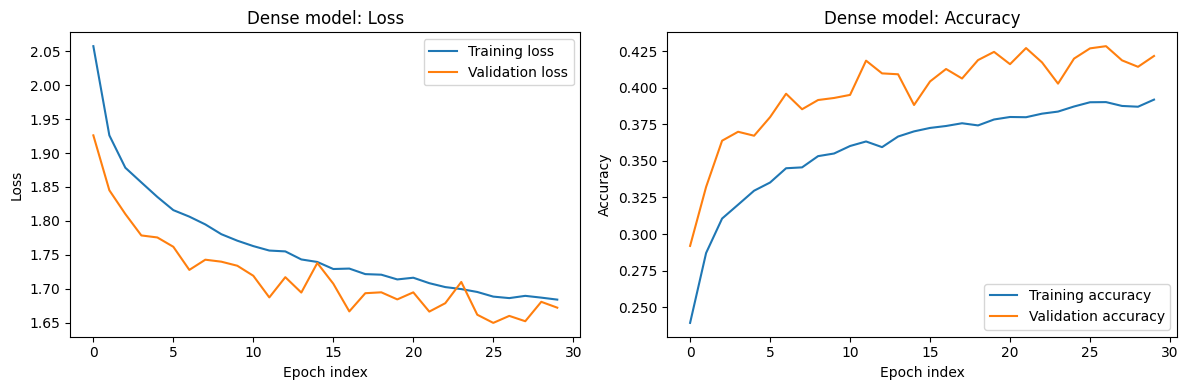

In [25]:
# Plot dense model learning curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_dense.history["loss"], label="Training loss")
plt.plot(history_dense.history["val_loss"], label="Validation loss")
plt.title("Dense model: Loss")
plt.xlabel("Epoch index")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_dense.history["accuracy"], label="Training accuracy")
plt.plot(history_dense.history["val_accuracy"], label="Validation accuracy")
plt.title("Dense model: Accuracy")
plt.xlabel("Epoch index")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [26]:
#  Evaluate dense model
dense_test_loss, dense_test_accuracy = dense_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

y_prob_dense = dense_model.predict(X_test, verbose=0)
y_pred_dense = y_prob_dense.argmax(axis=1)

dense_macro_f1 = f1_score(
    y_test,
    y_pred_dense,
    average="macro"
)

print(f"Dense model test loss: {dense_test_loss:.4f}")
print(f"Dense model test accuracy: {dense_test_accuracy:.2%}")
print(f"Dense model macro-F1: {dense_macro_f1:.4f}")

Dense model test loss: 1.6347
Dense model test accuracy: 43.34%
Dense model macro-F1: 0.4196


In [27]:
# Dense model classification report
print(classification_report(
    y_test,
    y_pred_dense,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

    airplane     0.5689    0.3920    0.4642      1000
  automobile     0.5476    0.5690    0.5581      1000
        bird     0.3144    0.1440    0.1975      1000
         cat     0.2937    0.3530    0.3206      1000
        deer     0.3347    0.5080    0.4035      1000
         dog     0.5993    0.1600    0.2526      1000
        frog     0.3917    0.5860    0.4696      1000
       horse     0.5550    0.4490    0.4964      1000
        ship     0.4840    0.6660    0.5606      1000
       truck     0.4424    0.5070    0.4725      1000

    accuracy                         0.4334     10000
   macro avg     0.4532    0.4334    0.4196     10000
weighted avg     0.4532    0.4334    0.4196     10000



<Figure size 1000x800 with 0 Axes>

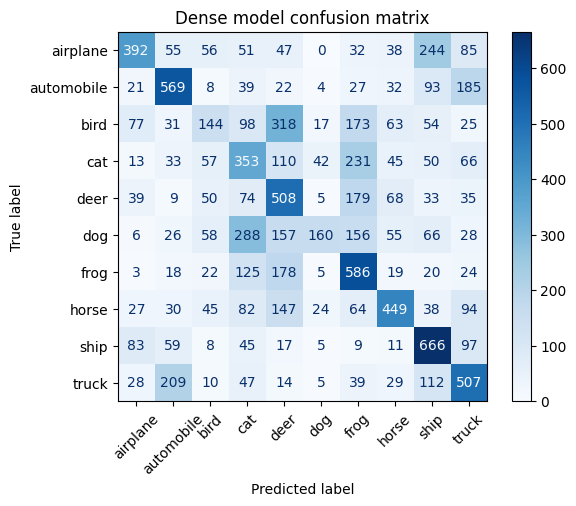

In [28]:
#  Dense model confusion matrix
cm_dense = confusion_matrix(y_test, y_pred_dense)

plt.figure(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm_dense,
    display_labels=class_names
).plot(
    values_format="d",
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Dense model confusion matrix")
plt.show()

In [32]:
#  Build CNN model
cnn_model = Sequential([
    Input(shape=(32,32,3)),
    
    Conv2D(32, kernel_size=(3,3), padding='same', activation='relu'),
    BatchNormalization(),
    Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),
    
    Conv2D(64, kernel_size=(3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    Conv2D(64, kernel_size=(3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),
    
    Conv2D(128, kernel_size=(3, 3), padding="same", activation="relu"),
    BatchNormalization(),

    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(10, activation="softmax")
    
    
])


cnn_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 32, 32, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 32, 32, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 32, 32, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 16, 16, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 16, 16, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 16, 16, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 8, 8, 128)           │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴──────────────

 Total params: 158,506 (619.16 KB)

 Trainable params: 157,866 (616.66 KB)

 Non-trainable params: 640 (2.50 KB)

In [35]:
# 32 × 32 × 3 image
#         ↓
# Conv2D: 32 filters
#         ↓
# Conv2D: 32 filters
#         ↓
# MaxPooling2D
#         ↓
# Conv2D: 64 filters
#         ↓
# Conv2D: 64 filters
#         ↓
# MaxPooling2D
#         ↓
# Conv2D: 128 filters
#         ↓
# GlobalAveragePooling2D
#         ↓
# Dense: 128 neurons + ReLU
#         ↓
# Dense: 10 neurons + softmax

# Why CNN is better for images
# A dense model treats pixels independently after flattening. 
# A CNN examines local regions and reuses the same filters across the image.

# Dense model:
# All 3,072 pixel values → Dense layers

# CNN model:
# Local image patches → Convolution filters → Feature maps

In [36]:
#  Add data augmentation
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator()

train_generator = train_datagen.flow(
    X_train,
    y_train,
    batch_size=64
)

val_generator = val_datagen.flow(
    X_val,
    y_val,
    batch_size=64
)

In [ ]:
# Train CNN with augmentation

history_cnn = cnn_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=50,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 93s 140ms/step - accuracy: 0.4393 - loss: 1.5334 - val_accuracy: 0.5069 - val_loss: 1.4013
Epoch 2/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 87s 139ms/step - accuracy: 0.5788 - loss: 1.1743 - val_accuracy: 0.5007 - val_loss: 1.5167
Epoch 3/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 89s 142ms/step - accuracy: 0.6345 - loss: 1.0399 - val_accuracy: 0.5919 - val_loss: 1.2372
Epoch 4/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 90s 144ms/step - accuracy: 0.6682 - loss: 0.9388 - val_accuracy: 0.6860 - val_loss: 0.9049
Epoch 5/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 87s 139ms/step - accuracy: 0.6898 - loss: 0.8848 - val_accuracy: 0.7382 - val_loss: 0.7521
Epoch 6/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 88s 141ms/step - accuracy: 0.7116 - loss: 0.8262 - val_accuracy: 0.7482 - val_loss: 0.7220
Epoch 7/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 88s 140ms/step - accuracy: 0.7267 - loss: 0.7846 - val_accuracy: 0.6997 - val_loss: 0.9080
Epoch 8/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 91s 145ms/step - accuracy: 0.7399 - loss: 0

In [ ]:
# Plot CNN learning curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["loss"], label="Training loss")
plt.plot(history_cnn.history["val_loss"], label="Validation loss")
plt.title("CNN: Loss")
plt.xlabel("Epoch index")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["accuracy"], label="Training accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation accuracy")
plt.title("CNN: Accuracy")
plt.xlabel("Epoch index")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate CNN
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

y_prob_cnn = cnn_model.predict(X_test, verbose=0)
y_pred_cnn = y_prob_cnn.argmax(axis=1)

cnn_macro_f1 = f1_score(
    y_test,
    y_pred_cnn,
    average="macro"
)

print(f"CNN test loss: {cnn_test_loss:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy:.2%}")
print(f"CNN macro-F1: {cnn_macro_f1:.4f}")

In [ ]:
# CNN classification report
print(classification_report(
    y_test,
    y_pred_cnn,
    target_names=class_names,
    digits=4
))

In [ ]:
# CNN confusion matrix
cm_cnn = confusion_matrix(y_test, y_pred_cnn)

plt.figure(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=class_names
).plot(
    values_format="d",
    cmap="Blues",
    xticks_rotation=45
)

plt.title("CNN confusion matrix")
plt.show()

In [ ]:
# Compare dense model and CNN
results = {
    "Dense model": {
        "Test accuracy": dense_test_accuracy,
        "Macro-F1": dense_macro_f1
    },
    "CNN model": {
        "Test accuracy": cnn_test_accuracy,
        "Macro-F1": cnn_macro_f1
    }
}

results_df = pd.DataFrame(results).T

results_df

In [ ]:
results_df.plot(
    kind="bar",
    figsize=(9, 5),
    color=["gray", "steelblue"]
)

plt.title("Dense model versus CNN")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

In [ ]:
# Analyze CNN mistakes
wrong_indices = np.where(y_pred_cnn != y_test)[0]

print(f"Number of misclassified test images: {len(wrong_indices)}")

plt.figure(figsize=(12, 12))

for i, idx in enumerate(wrong_indices[:16]):
    plt.subplot(4, 4, i + 1)
    plt.imshow(X_test[idx])
    plt.title(
        f"Actual: {class_names[y_test[idx]]}\n"
        f"Predicted: {class_names[y_pred_cnn[idx]]}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Save the best model
best_model = cnn_model

best_model.save("cifar10_best_model.keras")

print("Best model saved successfully.")

In [ ]:
# Load it later:
loaded_model = keras.models.load_model("cifar10_best_model.keras")

loaded_test_loss, loaded_test_accuracy = loaded_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Loaded-model test accuracy: {loaded_test_accuracy:.2%}")

In [ ]:
#  Predict one image
image_index = 0

single_image = X_test[image_index:image_index + 1]

probabilities = loaded_model.predict(
    single_image,
    verbose=0
)[0]

predicted_label = probabilities.argmax()

print("Predicted class:", class_names[predicted_label])
print("Actual class:", class_names[y_test[image_index]])

print("\nClass probabilities:")
for class_name, probability in zip(class_names, probabilities):
    print(f"{class_name}: {probability:.4f}")

In [ ]:
# Display the prediction
plt.figure()
plt.imshow(X_test[image_index])
plt.title(
    f"Predicted: {class_names[predicted_label]}\n"
    f"Actual: {class_names[y_test[image_index]]}"
)
plt.axis("off")
plt.show()